# UJI SENSITIVITAS P90-D3 — Tmax dan UTCImax di Sulawesi, 1996–2025
### Versi V2: peta jurnal SMOOTH mengikuti notebook spasial awal + grafik Spearman terpisah

**Indeks dan perhitungan tidak diubah.** P90-D3 tetap benchmark; HWF, penurunan (%) berbobot luas, Spearman ρ, dan Jaccard dihitung dari **grid ERA5 asli**. Hanya fungsi **pemetaan** yang dirombak mengikuti kode notebook `Heatwave_Sulawesi_1996_2025_Journal_Combined_SMOOTH.ipynb` serta `UTCI_Heatwave_Sulawesi_1996_2025_Journal_Combined_SMOOTH.ipynb`.

**Output utama skripsi:** (1) plot Spearman khusus; (2) panel ringkasan Spearman–persentase penurunan–Jaccard; (3) peta benchmark P90-D3 vs P95-D5 dan hilangnya HWF (2 × 3 panel); (4) peta lima skenario penurunan pada masing-masing indikator. Gambar pendukung: scatter P90-D3 vs P95-D5 dan perubahan hotspot.

**PENTING:** Untuk warna yang halus dan garis pantai akurat, gunakan SHP 6 provinsi pada Sel 1. Jika tidak ditemukan dan pustaka Cartopy beserta Natural Earth 10m tidak tersedia, notebook sengaja **memberi error** alih-alih diam-diam menampilkan peta kotak-kotak. Statistik tetap berasal dari grid asli.


### Koreksi tampilan skenario (plot kebalik)
Pada V2, dua plot ringkasan secara eksplisit memakai `ax.set_ylim(len(y)-.55,-.55)`, yang membalik sumbu Y kategori sehingga P90-D4 di atas dan P95-D5 di bawah. Versi ini menambahkan `STRICTEST_SCENARIO_ON_TOP=True` di Sel 1 untuk menampilkan P95-D5 di atas pada **kedua** plot ringkasan. Set `False` bila menginginkan urutan lama. **Koordinat peta dan semua nilai HWF/Spearman/Jaccard tidak dibalik atau diubah.**


## Persyaratan paket
Minimal: `numpy pandas xarray scipy matplotlib netCDF4 openpyxl`. Untuk peta: `geopandas shapely pyogrio` dengan **SHP Dukcapil berisi keenam provinsi Sulawesi**, atau `cartopy` dengan data *Natural Earth 10m* sebagai alternatif.

```bash
pip install numpy pandas xarray scipy matplotlib geopandas shapely pyogrio netCDF4 openpyxl
```

Jika tidak mempunyai SHP, dapat menggunakan `pip install cartopy` (pemanggilan data Natural Earth pertama kali mungkin memerlukan internet). Semua gambar memakai `DISPLAY_RENDER='smooth'`, dan tidak mengubah data perhitungan.


In [1]:
# SEL 1 — IMPORT & KONFIGURASI: PERIKSA PATH DI BAWAH INI
from pathlib import Path
import warnings, json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import colors, patheffects
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MultipleLocator
from scipy.stats import spearmanr, pearsonr
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', message='Mean of empty slice')

# Lokasi yang SAMA dengan notebook penelitian Merr.
TMAX_ROOT = Path(r'D:\MERLI\data\TMAX\HEATWAVE_JOURNAL_OUTPUT')
TMAX_CACHE = TMAX_ROOT / 'cache'
TMAX_RAW_DIR = Path(r'D:\MERLI\data\T2M Max')
UTCI_METRICS_FILE = (Path(r'D:\MERLI\data\UTCI_Hasil\UTCI_Heatwave_Journal_Combined_Output')
                     / 'data' / 'UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc')

# Folder OUTPUT BARU. Notebook lama tidak tertimpa.
OUTPUT_DIR = (Path(r'D:\MERLI\data\TMAX_UTCI_COMPARISON')
              / 'SENSITIVITAS_FINAL_SKRIPSI_P90D3')
PLOT_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
MAP_DIR = OUTPUT_DIR / 'maps_netcdf'
for f in [OUTPUT_DIR, PLOT_DIR, TABLE_DIR, MAP_DIR]:
    f.mkdir(parents=True, exist_ok=True)

# Jika file koordinat Tmax di luar data mentah, isi npz dengan array 'lat' dan 'lon'
TMAX_COORDS_NPZ = None
# Opsional SHP Dukcapil untuk masker halus dan batas provinsi (wajib untuk garis pantai halus yang akurat).
SULAWESI_SHP = Path(r'D:\MERLI\DRAFT\dem sulawesi\BATAS PROVINSI DESEMBER 2019 DUKCAPIL\BATAS PROVINSI DESEMBER 2019 DUKCAPIL\BATAS_PROVINSI_DESEMBER_2019_DUKCAPIL.shp')

START_YEAR, END_YEAR = 1996, 2025
YEARS = np.arange(START_YEAR, END_YEAR + 1)
SCENARIOS = ['P90_D3','P90_D4','P90_D5','P95_D3','P95_D4','P95_D5']
BENCHMARK = 'P90_D3'
OTHER_SCENARIOS = [s for s in SCENARIOS if s != BENCHMARK]
# PILIHAN ORIENTASI PLOT SENSITIVITAS (hanya mengubah tampilan, bukan data):
# True : P95-D5 (paling ketat) di baris PALING ATAS.
# False: P90-D4 (paling ringan) di baris PALING ATAS.
STRICTEST_SCENARIO_ON_TOP = True
HOTSPOT_TOP_FRACTION = .20
MAP_EXTENT = [118.,127.,-7.,2.5]
STRICT_QC = True
FIG_DPI = 400          # untuk ekspor PNG publikasi
SAVE_PDF = True        # PDF vektor cocok untuk jurnal
SHOW_INLINE = True     # SEMUA gambar langsung muncul saat Run All

mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif'],
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.labelsize': 9,
    'axes.edgecolor': '#303845',
    'axes.linewidth': .8,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'xtick.color': '#445064', 'ytick.color': '#445064',
    'grid.linewidth': .4,
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})
PALETTE = {'Tmax':'#bc5c38', 'UTCImax':'#246e88'}

print('Benchmark:',BENCHMARK,'| Periode:',START_YEAR,'–',END_YEAR)
print('Folder hasil:',OUTPUT_DIR)
print('SHOW_INLINE =',SHOW_INLINE,'| Resolusi PNG =',FIG_DPI,'dpi')
# Render spasial: 'smooth' hanya jika SHP tersedia; fallback otomatis ke grid asli.
DISPLAY_RENDER = 'smooth'
DISPLAY_NX, DISPLAY_NY = 650, 700
STRICT_SMOOTH_MAP = True   # Fail jelas bila SHP / Natural Earth 10m tidak ada
MAKE_OPTIONAL_HOTSPOT_FIGURE = True

Benchmark: P90_D3 | Periode: 1996 – 2025
Folder hasil: D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3
SHOW_INLINE = True | Resolusi PNG = 400 dpi


## 1 — Periksa input dan baca HWF asli
Data metrik disimpan per skenario. **P90-D3** merupakan benchmark internal, bukan standar universal yang dianggap paling benar. QC menuntut 30 tahun lengkap pada grid yang sama untuk semua enam skenario **di dalam indikator yang sama**. Tmax dan UTCImax tetap menggunakan grid native masing-masing.

In [2]:
# SEL 2 — PERIKSA INPUT
inputs = {s: TMAX_CACHE / f'metrics_{s}_W15_{START_YEAR}_{END_YEAR}.npz' for s in SCENARIOS}
missing = [str(v) for v in inputs.values() if not v.is_file()]
if not UTCI_METRICS_FILE.is_file():
    missing.append(str(UTCI_METRICS_FILE))
if TMAX_COORDS_NPZ is None:
    raw_candidates = sorted(TMAX_RAW_DIR.glob('*.nc')) if TMAX_RAW_DIR.is_dir() else []
    if not raw_candidates:
        missing.append(f'File contoh .nc pada {TMAX_RAW_DIR} ATAU isi TMAX_COORDS_NPZ')
else:
    if not Path(TMAX_COORDS_NPZ).is_file():
        missing.append(str(TMAX_COORDS_NPZ))

if missing:
    raise FileNotFoundError(
        'Berkas input belum lengkap. Periksa SEL 1 atau jalankan dahulu notebook utama.\n'
        + '\n'.join(' - ' + x for x in missing)
    )
print('Semua file input ditemukan.')
for s, f in inputs.items():
    print('TMAX', s, '|', f.name)
print('UTCI |', UTCI_METRICS_FILE.name)

Semua file input ditemukan.
TMAX P90_D3 | metrics_P90_D3_W15_1996_2025.npz
TMAX P90_D4 | metrics_P90_D4_W15_1996_2025.npz
TMAX P90_D5 | metrics_P90_D5_W15_1996_2025.npz
TMAX P95_D3 | metrics_P95_D3_W15_1996_2025.npz
TMAX P95_D4 | metrics_P95_D4_W15_1996_2025.npz
TMAX P95_D5 | metrics_P95_D5_W15_1996_2025.npz
UTCI | UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc


In [3]:
# SEL 3 — FUNGSI PEMBACAAN / QC

def normalize_coords(latitude, longitude):
    latitude = np.asarray(latitude, dtype=float)
    longitude = np.asarray(longitude, dtype=float)
    longitude = np.where(longitude > 180, ((longitude + 180) % 360) - 180, longitude)
    if latitude.ndim != 1 or longitude.ndim != 1:
        raise ValueError('Latitude dan longitude harus satu dimensi.')
    return latitude, longitude


def load_tmax_geocoords(shape2d):
    if TMAX_COORDS_NPZ is not None:
        with np.load(TMAX_COORDS_NPZ) as z:
            lat = np.asarray(z['lat'], dtype=float)
            lon = np.asarray(z['lon'], dtype=float)
        # npz opsi ini memang sudah dalam urutan cache.
    else:
        ds_coord = xr.open_dataset(raw_candidates[0], decode_times=False)
        try:
            lat_name = next((c for c in ['latitude', 'lat', 'Latitude', 'LAT'] if c in ds_coord), None)
            lon_name = next((c for c in ['longitude', 'lon', 'Longitude', 'LON'] if c in ds_coord), None)
            if not lat_name or not lon_name:
                raise KeyError('Koordinat Tmax latitude/longitude tidak ditemukan pada file mentah.')
            lat = ds_coord[lat_name].values
            lon = ds_coord[lon_name].values
        finally:
            ds_coord.close()
        lat, lon = normalize_coords(lat, lon)
        # Cache Tmax diproses dengan sort ascending KEDUA koordinatnya.
        lat = lat[np.argsort(lat)]
        lon = lon[np.argsort(lon)]
    if (len(lat), len(lon)) != shape2d:
        raise ValueError(
            f'Koordinat Tmax {len(lat)}x{len(lon)} tidak cocok dengan cache {shape2d}. '
            'Periksa referensi berkas mentah yang dipilih.'
        )
    if np.any(np.diff(lat) <= 0) or np.any(np.diff(lon) <= 0):
        raise ValueError('Urutan koordinat cache Tmax harus ascending.')
    return lat, lon


def load_tmax_hwf():
    blocks = []
    for scen in SCENARIOS:
        with np.load(inputs[scen]) as z:
            if 'HWF' not in z or 'years' not in z:
                raise KeyError(f'Cache {scen} tidak memiliki HWF/years.')
            years = np.asarray(z['years'], dtype=int)
            values = np.asarray(z['HWF'], dtype=np.float32)
        if not np.array_equal(years, YEARS):
            raise ValueError(f'Tahun pada cache {scen} tidak sesuai {START_YEAR}–{END_YEAR}.')
        if values.ndim != 3 or values.shape[0] != len(YEARS):
            raise ValueError(f'Shape HWF Tmax {scen} tidak sesuai (30, lat, lon): {values.shape}')
        if blocks and values.shape != blocks[0].shape:
            raise ValueError(f'Shape grid HWF Tmax berubah pada skenario {scen}.')
        blocks.append(values)
    cube = np.stack(blocks, axis=0)  # (scenario, year, lat, lon)
    lat, lon = load_tmax_geocoords(cube.shape[-2:])
    return cube, lat, lon


def load_utci_hwf():
    ds = xr.open_dataset(UTCI_METRICS_FILE, decode_timedelta=False)
    try:
        if 'HWF' not in ds:
            raise KeyError('Variabel HWF tidak ditemukan pada metrik UTCI.')
        da = ds['HWF']
        expected_dims = {'percentile', 'min_duration', 'year', 'latitude', 'longitude'}
        if set(da.dims) != expected_dims:
            raise ValueError(f'Dimensi UTCI tidak sesuai: {da.dims}')
        arrs = []
        for scen in SCENARIOS:
            p, d = [int(x) for x in scen.replace('P', '').split('_D')]
            arr = da.sel(percentile=p, min_duration=d).transpose('year', 'latitude', 'longitude')
            years = np.asarray(arr['year'].values, dtype=int)
            if not np.array_equal(years, YEARS):
                raise ValueError(f'Tahun UTCI {scen} tidak lengkap atau urutannya berbeda.')
            arrs.append(np.asarray(arr.values, dtype=np.float32))
        cube = np.stack(arrs, axis=0)
        lat, lon = normalize_coords(ds['latitude'].values, ds['longitude'].values)
        li, lj = np.argsort(lat), np.argsort(lon)
        cube = cube[:, :, li, :][:, :, :, lj]
        lat, lon = lat[li], lon[lj]
    finally:
        ds.close()
    if np.any(np.diff(lat) <= 0) or np.any(np.diff(lon) <= 0):
        raise ValueError('Koordinat UTCI tidak unik/ascending setelah normalisasi.')
    return cube, lat, lon


def annual_cube_to_maps(cube, name):
    # Memakai grid dengan 30 tahun lengkap untuk KEENAM skenario.
    valid = np.all(np.isfinite(cube), axis=(0, 1))
    if np.count_nonzero(valid) < 10:
        raise ValueError(f'{name}: terlalu sedikit grid dengan 30 tahun HWF lengkap.')
    if np.any(cube[:, :, valid] < 0):
        raise ValueError(f'{name}: ditemukan HWF negatif.')
    if np.any(cube[:, :, valid] > 366):
        raise ValueError(f'{name}: ditemukan HWF > 366 hari/tahun.')
    maps = np.mean(cube, axis=1, dtype=np.float64)
    maps[:, ~valid] = np.nan
    return maps, valid


def validate_nested_scenarios(maps, valid, name):
    # Ketatnya kriteria bertambah: HWF tidak boleh meningkat.
    pairs = [('P90_D3', 'P90_D4'), ('P90_D4', 'P90_D5'),
             ('P95_D3', 'P95_D4'), ('P95_D4', 'P95_D5'),
             ('P90_D3', 'P95_D3'), ('P90_D4', 'P95_D4'), ('P90_D5', 'P95_D5')]
    violations = []
    for loose, strict in pairs:
        a, b = maps[SCENARIOS.index(loose)], maps[SCENARIOS.index(strict)]
        bad = (b[valid] - a[valid]) > 1e-5
        if np.any(bad):
            violations.append(f'{loose} → {strict}: {int(bad.sum())} grid')
    if violations:
        msg = f'{name}: HWF tidak monoton! ' + '; '.join(violations)
        if STRICT_QC:
            raise ValueError(msg + '. Periksa input/output metrik atau definisi kejadian.')
        warnings.warn(msg)
    else:
        print(f'{name}: QC nested-scenarios LULUS.')
    return violations

In [4]:
# SEL 4 — LOAD DATA NYATA DARI WORKFLOW SKRIPSI
collections = {}
for indikator, loader in [('Tmax', load_tmax_hwf), ('UTCImax', load_utci_hwf)]:
    cube, lat, lon = loader()
    maps, valid = annual_cube_to_maps(cube, indikator)
    violations = validate_nested_scenarios(maps, valid, indikator)
    collections[indikator] = {
        'maps': maps, 'valid': valid, 'lat': lat, 'lon': lon,
        'years': YEARS.copy(), 'violations': violations,
    }
    print(f'{indikator:8s} | grid={maps.shape[-2:]} | valid={valid.sum()} '
          f'| HWF P90-D3 mean={np.nanmean(maps[0]):.2f} hari/tahun')
    del cube

Tmax: QC nested-scenarios LULUS.
Tmax     | grid=(57, 45) | valid=242 | HWF P90-D3 mean=14.91 hari/tahun
UTCImax: QC nested-scenarios LULUS.
UTCImax  | grid=(44, 32) | valid=242 | HWF P90-D3 mean=9.12 hari/tahun


## 2 — Statistik sensitivitas: perubahan HWF, Spearman, dan hotspot Jaccard

- **Penurunan regional (%)** = 100 × (rerata berbobot HWF P90-D3 − rerata HWF skenario) / rerata HWF P90-D3. Pembobotan berdasarkan kosinus lintang, tanpa interpolasi.
- **Spearman ρ:** kesesuaian peringkat klimatologi HWF antargrid skenario terhadap P90-D3. Dihitung dari pasangan grid valid yang sama, bukan dari nilai smoothed.
- **Jaccard:** irisan ÷ gabungan grid hotspot. Hotspot = **20% teratas** dari grid dengan HWF positif di masing-masing skenario. Nilai 1 = hotspot identik, 0 = tak beririsan.

HWF P90-D3 = 0 pada suatu grid menyebabkan **persen penurunan grid tersebut tidak terdefinisi** (NaN). Grid ini tetap masuk perhitungan rerata regional. Korelasi spasial dilaporkan secara **deskriptif**, sebab sel grid bertetangga memiliki autokorelasi spasial.

In [5]:
# SEL 5 — FUNGSI STATISTIK (KORELASI, SELISIH, HOTSPOT)

def area_mean(z, latitude, grid_mask):
    w = np.broadcast_to(np.cos(np.deg2rad(latitude))[:, None], z.shape)
    m = grid_mask & np.isfinite(z) & np.isfinite(w)
    if not np.any(m):
        return np.nan
    return float(np.sum(z[m] * w[m]) / np.sum(w[m]))


def safe_correlations(a, b, mask):
    x, y = a[mask], b[mask]
    if x.size < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan, np.nan
    return float(spearmanr(x, y).statistic), float(pearsonr(x, y).statistic)


def hotspot_mask(arr, mask, fraction):
    eligible = mask & np.isfinite(arr) & (arr > 0)
    hotspot = np.zeros(arr.shape, dtype=bool)
    if not np.any(eligible):
        return hotspot, np.nan
    cut = float(np.quantile(arr[eligible], 1.0 - fraction))
    hotspot[eligible] = arr[eligible] >= cut - 1e-10
    return hotspot, cut


def compute_one_indicator(name, col):
    lat, lon, valid = col['lat'], col['lon'], col['valid']
    maps = col['maps']
    base = maps[SCENARIOS.index(BENCHMARK)]
    weights_mask = valid & np.isfinite(base)
    baseline_hot, base_cut = hotspot_mask(base, weights_mask, HOTSPOT_TOP_FRACTION)
    base_regional = area_mean(base, lat, weights_mask)

    results = {}
    rows = []
    for i, scen in enumerate(SCENARIOS):
        field = maps[i]
        common = weights_mask & np.isfinite(field)
        diff = np.where(common, field - base, np.nan)
        reduction_pct = np.full(base.shape, np.nan, dtype=float)
        eligible = common & (base > 0)
        reduction_pct[eligible] = 100.0 * (base[eligible] - field[eligible]) / base[eligible]
        rho, r = safe_correlations(base, field, common)

        hot, hot_cut = hotspot_mask(field, common, HOTSPOT_TOP_FRACTION)
        # Kategori 0: bukan hotspot, 1: baseline saja, 2: skenario saja, 3: keduanya.
        classes = np.zeros(base.shape, dtype=np.int8)
        classes[baseline_hot & ~hot] = 1
        classes[~baseline_hot & hot] = 2
        classes[baseline_hot & hot] = 3
        classes[~common] = -1
        union = baseline_hot | hot
        intersection = baseline_hot & hot
        union_n = int(union.sum())
        inter_n = int(intersection.sum())
        base_n = int(baseline_hot.sum())
        alt_n = int(hot.sum())
        jaccard = inter_n / union_n if union_n else np.nan
        retention = 100 * inter_n / base_n if base_n else np.nan

        scenario_regional = area_mean(field, lat, common)
        reg_reduction = (100 * (base_regional - scenario_regional) / base_regional
                         if np.isfinite(base_regional) and base_regional > 0 else np.nan)
        results[scen] = {
            'hwf': field, 'delta': diff, 'reduction': reduction_pct,
            'hotspot': hot, 'hotspot_class': classes,
            'spearman': rho, 'pearson': r, 'jaccard': jaccard,
        }
        rows.append({
            'indicator': name, 'scenario': scen,
            'n_valid_grid': int(common.sum()),
            'n_benchmark_positive_grid': int(eligible.sum()),
            'benchmark_hwf_area_mean_days_per_year': base_regional,
            'scenario_hwf_area_mean_days_per_year': scenario_regional,
            'delta_hwf_area_mean_days_per_year': scenario_regional - base_regional,
            'reduction_regional_percent': reg_reduction,
            'median_grid_reduction_percent': float(np.median(reduction_pct[eligible])) if eligible.any() else np.nan,
            'spearman_rho': rho, 'pearson_r': r,
            'benchmark_hotspot_cutoff_days_per_year': base_cut,
            'scenario_hotspot_cutoff_days_per_year': hot_cut,
            'n_baseline_hotspot': base_n, 'n_scenario_hotspot': alt_n,
            'n_hotspot_overlap': inter_n, 'hotspot_jaccard': jaccard,
            'hotspot_retention_percent': retention,
        })
    return results, pd.DataFrame(rows)

statistics = {}
frames = []
for indicator, col in collections.items():
    result, table = compute_one_indicator(indicator, col)
    statistics[indicator] = result
    frames.append(table)
summary_df = pd.concat(frames, ignore_index=True)

display(summary_df[['indicator','scenario','spearman_rho','pearson_r',
                    'reduction_regional_percent','hotspot_jaccard',
                    'hotspot_retention_percent']].round(3))

,indicator,scenario,spearman_rho,pearson_r,reduction_regional_percent,hotspot_jaccard,hotspot_retention_percent
0,Tmax,P90_D3,1.000,1.000,0.000,1.000,100.000
1,Tmax,P90_D4,0.935,0.948,32.573,0.750,85.714
2,Tmax,P90_D5,0.895,0.912,52.379,0.623,77.551
3,Tmax,P95_D3,0.849,0.864,63.001,0.633,77.551
4,Tmax,P95_D4,0.773,0.810,78.030,0.562,73.469
5,Tmax,P95_D5,0.696,0.739,86.180,0.463,63.265
6,UTCImax,P90_D3,1.000,1.000,0.000,1.000,100.000
7,UTCImax,P90_D4,0.958,0.964,44.175,0.887,95.918
8,UTCImax,P90_D5,0.928,0.934,67.480,0.690,81.633
9,UTCImax,P95_D3,0.920,0.924,68.710,0.800,89.796


In [6]:
# TABEL UTAMA — hasil asli dihitung ulang dari file metrik
main_table = (summary_df[['indicator', 'scenario',
                          'benchmark_hwf_area_mean_days_per_year',
                          'scenario_hwf_area_mean_days_per_year',
                          'reduction_regional_percent', 'spearman_rho',
                          'hotspot_jaccard']]
              .rename(columns={
                  'indicator':'Indikator',
                  'scenario':'Skenario',
                  'benchmark_hwf_area_mean_days_per_year':'HWF P90-D3 (hari/tahun)',
                  'scenario_hwf_area_mean_days_per_year':'HWF skenario (hari/tahun)',
                  'reduction_regional_percent':'Penurunan HWF (%)',
                  'spearman_rho':'Spearman rho',
                  'hotspot_jaccard':'Jaccard'}))
print('Tabel perbandingan terhadap benchmark P90-D3:')
display(main_table.round(3))
TABLE_DIR.mkdir(parents=True, exist_ok=True)
main_table.to_csv(TABLE_DIR / 'TABEL_UTAMA_SENSITIVITAS_P90D3.csv', index=False)
try:
    main_table.to_excel(TABLE_DIR / 'TABEL_UTAMA_SENSITIVITAS_P90D3.xlsx', index=False)
except ImportError:
    print('Excel dilewati: instal openpyxl bila diperlukan.')

Tabel perbandingan terhadap benchmark P90-D3:


,Indikator,Skenario,HWF P90-D3 (hari/tahun),HWF skenario (hari/tahun),Penurunan HWF (%),Spearman rho,Jaccard
0,Tmax,P90_D3,14.908,14.908,0.000,1.000,1.000
1,Tmax,P90_D4,14.908,10.052,32.573,0.935,0.750
2,Tmax,P90_D5,14.908,7.099,52.379,0.895,0.623
3,Tmax,P95_D3,14.908,5.516,63.001,0.849,0.633
4,Tmax,P95_D4,14.908,3.275,78.030,0.773,0.562
5,Tmax,P95_D5,14.908,2.060,86.180,0.696,0.463
6,UTCImax,P90_D3,9.114,9.114,0.000,1.000,1.000
7,UTCImax,P90_D4,9.114,5.088,44.175,0.958,0.887
8,UTCImax,P90_D5,9.114,2.964,67.480,0.928,0.690
9,UTCImax,P95_D3,9.114,2.852,68.710,0.920,0.800


## Peta spasial smooth — gaya notebook Tmax/UTCI sebelumnya

- **Daratan** di-mask dengan poligon enam provinsi, bukan batas kotak sel raster.
- **Interpolasi linear** dan nearest pada tepi hanya untuk gambar. Mask *native-valid footprint* mempertahankan ruang tanpa data.
- **Sumber batas:** shapefile Dukcapil sesuai path Sel 1 (prioritas); alternatif Cartopy Natural Earth 10m (6 provinsi).
- Jika keduanya tidak tersedia, notebook berhenti dengan pesan penjelasan: tidak ada *fallback* diam-diam ke plot kotak-kotak.
- **Grid statistik tetap asli**. Spearman/Jaccard dihitung sebelum peta dibuat, bukan pada raster yang dihaluskan.


In [7]:
# SEL 6 — PLOT KARTOGRAFI SULAWESI: SOURCE-MATCHED, 10m, SMOOTH
# Adaptasi dari notebook SMOOTH Tmax dan UTCI: linear + land polygon + native footprint.
# SHP prioritas; Natural Earth Cartopy bila SHP tidak tersedia.
from scipy.interpolate import griddata, RegularGridInterpolator
from matplotlib.colors import Normalize, ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.cm import ScalarMappable
import matplotlib.patches as mpatches
from shapely.ops import unary_union

try:
    import geopandas as gpd
except ImportError:
    gpd = None
try:
    import cartopy.crs as ccrs
    import cartopy.io.shapereader as shpreader
    HAS_CARTOPY = True
except ImportError:
    ccrs, shpreader, HAS_CARTOPY = None, None, False

try:
    from shapely import contains_xy as _contains_xy
except ImportError:
    try:
        from shapely.vectorized import contains as _contains_xy
    except ImportError:
        _contains_xy = None

TARGET_PROVINCES = ('SULAWESI UTARA', 'GORONTALO', 'SULAWESI TENGAH',
                    'SULAWESI BARAT', 'SULAWESI SELATAN', 'SULAWESI TENGGARA')
PROV_GDF, PROVINCE_GEOMETRIES = None, []
SULAWESI_GEOM, GEOMETRY_SOURCE = None, None

if SULAWESI_SHP is not None and Path(SULAWESI_SHP).is_file():
    if gpd is None:
        raise ImportError('Pasang geopandas: pip install geopandas pyogrio')
    _geo = gpd.read_file(SULAWESI_SHP)
    if _geo.crs is None or 'PROVINSI' not in _geo.columns:
        raise ValueError('SHP harus memiliki CRS dan kolom PROVINSI.')
    _geo = _geo.to_crs('EPSG:4326')
    _names = _geo['PROVINSI'].astype(str).str.upper().str.strip().str.replace(r'\s+', ' ', regex=True)
    _geo = _geo.loc[_names.isin(TARGET_PROVINCES)].copy()
    _geo['_nama'] = _names.loc[_geo.index]
    if _geo['_nama'].nunique() != 6:
        raise ValueError('SHP yang dipilih tidak memuat lengkap 6 provinsi Sulawesi.')
    PROV_GDF = _geo.dissolve(by='_nama').reset_index()
    PROVINCE_GEOMETRIES = list(PROV_GDF.geometry)
    SULAWESI_GEOM = unary_union(PROVINCE_GEOMETRIES)
    GEOMETRY_SOURCE = 'SHP Dukcapil: 6 provinsi'
else:
    if HAS_CARTOPY:
        try:
            _path = shpreader.natural_earth(
                resolution='10m', category='cultural', name='admin_1_states_provinces')
            _recs = list(shpreader.Reader(_path).records())
            _province = {}
            _name_aliases = {
                'SULAWESI UTARA': ('north sulawesi', 'sulawesi utara'),
                'GORONTALO': ('gorontalo',),
                'SULAWESI TENGAH': ('central sulawesi','sulawesi tengah'),
                'SULAWESI BARAT': ('west sulawesi','sulawesi barat'),
                'SULAWESI SELATAN': ('south sulawesi','sulawesi selatan'),
                'SULAWESI TENGGARA': ('southeast sulawesi','sulawesi tenggara')}
            for _rec in _recs:
                _text = ' '.join(str(v).lower() for v in _rec.attributes.values() if v is not None)
                if 'indonesia' not in _text and 'idn' not in _text:
                    continue
                for _key, _aliases in _name_aliases.items():
                    if _key not in _province and any(a in _text for a in _aliases):
                        _province[_key] = _rec.geometry
            if len(_province) == 6:
                PROVINCE_GEOMETRIES = list(_province.values())
                SULAWESI_GEOM = unary_union(PROVINCE_GEOMETRIES)
                GEOMETRY_SOURCE = 'Natural Earth Admin-1 10m (Cartopy)'
            else:
                print('Natural Earth: hanya tersedia',len(_province),'/6 provinsi; tidak dipakai untuk mask.')
        except Exception as exc:
            warnings.warn('Batas Natural Earth belum tersedia: '+str(exc))

if (SULAWESI_GEOM is None or _contains_xy is None) and DISPLAY_RENDER == 'smooth':
    msg = ('SMOOTH membutuhkan batas daratan Sulawesi yang valid.\n'
           'Perbaiki SULAWESI_SHP di Sel 1 ke SHP Dukcapil atau pasang cartopy + Natural Earth 10m.\n'
           'Notebook lama diam-diam fallback ke kotak-kotak; versi ini tidak.')
    if STRICT_SMOOTH_MAP:
        raise RuntimeError(msg)
    warnings.warn(msg + '\nMencoba native untuk QC saja.')
    EFFECTIVE_RENDER = 'native'
else:
    EFFECTIVE_RENDER = DISPLAY_RENDER

print('Batas daratan:', GEOMETRY_SOURCE or 'belum tersedia')
print('Mode gambar:', EFFECTIVE_RENDER, '| Mode analisis: native (tanpa interpolasi)')
_FINE_CACHE = {}

def _smooth_display(indicator, field):
    col = collections[indicator]
    lat, lon = col['lat'], col['lon']
    z = np.asarray(field, dtype=float).copy()
    z[~col['valid']] = np.nan
    if EFFECTIVE_RENDER == 'native':
        return lon, lat, np.ma.masked_invalid(z)
    if indicator not in _FINE_CACHE:
        x = np.linspace(MAP_EXTENT[0], MAP_EXTENT[1], DISPLAY_NX)
        y = np.linspace(MAP_EXTENT[2], MAP_EXTENT[3], DISPLAY_NY)
        xx, yy = np.meshgrid(x, y)
        inside = np.asarray(_contains_xy(SULAWESI_GEOM, xx, yy), dtype=bool)
        _FINE_CACHE[indicator] = (x, y, xx, yy, inside)
    x, y, xx, yy, land = _FINE_CACHE[indicator]
    valid = np.isfinite(z)
    if np.count_nonzero(valid) < 4:
        raise ValueError(f'{indicator}: < 4 sel native valid tidak bisa diinterpolasi.')
    gx, gy = np.meshgrid(lon, lat)
    pts = np.column_stack((gx[valid], gy[valid]))
    fine = griddata(pts, z[valid], (xx, yy), method='linear')
    edges = land & ~np.isfinite(fine)
    if np.any(edges):
        closest = griddata(pts, z[valid], (xx, yy), method='nearest')
        fine[edges] = closest[edges]
    # Area tanpa grid valid asli akan tetap kosong di hasil visual.
    support = RegularGridInterpolator(
        (lat, lon), valid.astype('uint8'), method='nearest',
        bounds_error=False, fill_value=0,
    )(np.column_stack((yy.ravel(), xx.ravel()))).reshape(xx.shape).astype(bool)
    fine[~(land & support)] = np.nan
    return x, y, np.ma.masked_invalid(fine)


def make_map_axis(fig, spec):
    if HAS_CARTOPY:
        return fig.add_subplot(spec, projection=ccrs.PlateCarree())
    return fig.add_subplot(spec)


def decorate_map(ax, title='', left=True, bottom=True):
    ax.set_facecolor('#edf3f7')
    if HAS_CARTOPY:
        ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
        # Geo coast 10m sama dengan notebook awal. Bila offline, batas poligon SHP tetap digambar.
        try:
            ax.coastlines(resolution='10m', linewidth=.58, color='#343e46', zorder=6)
        except Exception:
            pass
        for poly in PROVINCE_GEOMETRIES:
            ax.add_geometries([poly], crs=ccrs.PlateCarree(), facecolor='none',
                              edgecolor='#34444b', linewidth=.48, zorder=7)
        gl = ax.gridlines(draw_labels=True,linewidth=.35,linestyle=':',
                          alpha=.42,x_inline=False,y_inline=False)
        gl.top_labels=False; gl.right_labels=False
        gl.left_labels=left; gl.bottom_labels=bottom
        gl.xlabel_style={'size':8}; gl.ylabel_style={'size':8}
    else:
        ax.set_xlim(MAP_EXTENT[0],MAP_EXTENT[1]); ax.set_ylim(MAP_EXTENT[2],MAP_EXTENT[3])
        ax.set_aspect(1/np.cos(np.radians(-2.0)))
        if PROV_GDF is not None:
            PROV_GDF.boundary.plot(ax=ax,color='#34444b',linewidth=.58,zorder=7)
        else:
            from shapely.geometry import MultiPolygon
            from matplotlib.path import Path as MplPath
            from matplotlib.patches import PathPatch
            for geom in PROVINCE_GEOMETRIES:
                seq = geom.geoms if isinstance(geom,MultiPolygon) else [geom]
                for pg in seq:
                    X,Y = pg.exterior.xy
                    ax.plot(X,Y,color='#34444b',lw=.55,zorder=7)
        ax.set_xticks([118,120,122,124,126]); ax.set_yticks([-6,-4,-2,0,2])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:g}°BT'))
        ax.yaxis.set_major_formatter(FuncFormatter(
            lambda v,pos:'0°' if abs(v)<1e-6 else f'{abs(v):g}°'+('LU' if v>0 else 'LS')))
        ax.tick_params(labelleft=left,labelbottom=bottom,labelsize=8,length=2)
        ax.grid(ls=':',lw=.35,alpha=.4,color='#8096a6')
    ax.set_title(title,loc='left',fontsize=10,weight='bold',pad=7)
    for s in ax.spines.values():s.set_linewidth(.72)


def draw_continuous(ax, indicator, field, cmap, norm):
    lo,la,zz=_smooth_display(indicator,field)
    cm=mpl.colormaps[cmap].copy()
    cm.set_bad('white',alpha=0)
    kw={'cmap':cm,'norm':norm,'zorder':2,'rasterized':True}
    if HAS_CARTOPY:
        kw['transform']=ccrs.PlateCarree()
    return ax.pcolormesh(lo,la,zz,shading='auto' if EFFECTIVE_RENDER=='smooth' else 'nearest',**kw)


def save_figure(fig,stem):
    target=PLOT_DIR/(stem+'.png')
    fig.savefig(target,dpi=FIG_DPI,bbox_inches='tight',facecolor='white')
    if SAVE_PDF:fig.savefig(target.with_suffix('.pdf'),bbox_inches='tight',facecolor='white')
    print('✓',target)
    if SHOW_INLINE:plt.show()
    plt.close(fig)
    return target


Batas daratan: Natural Earth Admin-1 10m (Cartopy)
Mode gambar: smooth | Mode analisis: native (tanpa interpolasi)


## Gambar Utama 1 — Sintesis sensitivitas (PALING PENTING)
**Disarankan masuk Bab III.** Satu visual ini memperlihatkan kestabilan peringkat spasial (**Spearman ρ**), penurunan HWF regional (**%**), dan ketahanan lokasi hotspot (**Jaccard**), untuk masing-masing definisi terhadap P90-D3. Semua indikator dihitung pada grid native.

✓ D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures\FIG01_MAIN_Comparison_Spearman_HWF_Jaccard.png


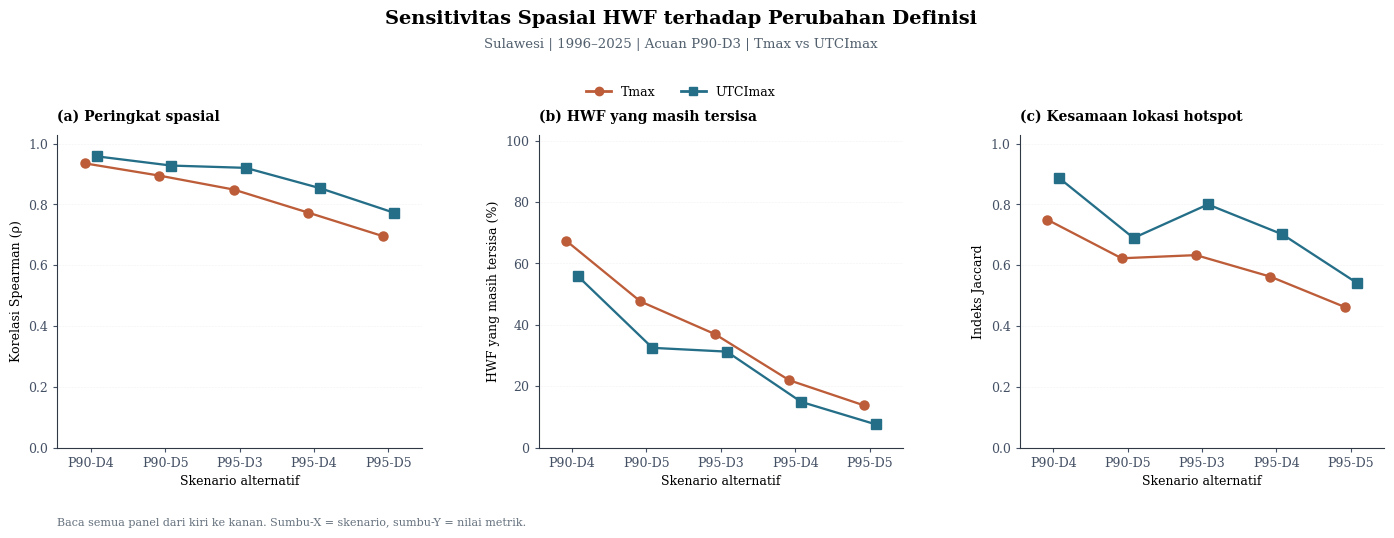

WindowsPath('D:/MERLI/data/TMAX_UTCI_COMPARISON/SENSITIVITAS_FINAL_SKRIPSI_P90D3/figures/FIG01_MAIN_Comparison_Spearman_HWF_Jaccard.png')

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 5.8), facecolor='white')
fig.subplots_adjust(left=.07, right=.985, bottom=.22, top=.76, wspace=.32)

scenario_labels = [s.replace('_', '-') for s in OTHER_SCENARIOS]
x = np.arange(len(OTHER_SCENARIOS), dtype=float)
metrics = [
    ('spearman_rho', 'Korelasi Spearman (ρ)', (0, 1.03), '(a) Peringkat spasial'),
    ('hwf_remaining_percent', 'HWF yang masih tersisa (%)', (0, 102), '(b) HWF yang masih tersisa'),
    ('hotspot_jaccard', 'Indeks Jaccard', (0, 1.03), '(c) Kesamaan lokasi hotspot')
]
offsets = {'Tmax': -0.08, 'UTCImax': 0.08}
markers = {'Tmax': 'o', 'UTCImax': 's'}

for ax, (metric, ylabel, ylim, title) in zip(axes, metrics):
    for ind in ['Tmax', 'UTCImax']:
        df = (summary_df.query('indicator == @ind')
              .set_index('scenario')
              .reindex(OTHER_SCENARIOS))

        if metric == 'hwf_remaining_percent':
            vals = 100.0 - df['reduction_regional_percent'].to_numpy(dtype=float)
        else:
            vals = df[metric].to_numpy(dtype=float)

        ax.plot(x + offsets[ind], vals,
                marker=markers[ind], markersize=6.5, lw=1.65,
                color=PALETTE[ind], label=ind)

    ax.set_xticks(x, scenario_labels)
    ax.set_xlim(-0.45, len(x) - 0.55)
    ax.set_ylim(*ylim)
    ax.set_title(title, loc='left', weight='bold', fontsize=10, pad=10)
    ax.set_xlabel('Skenario alternatif', fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(axis='y', ls=':', alpha=.3)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Sensitivitas Spasial HWF terhadap Perubahan Definisi',
             y=.975, fontsize=14, weight='bold')
fig.text(.5, .91, 'Sulawesi | 1996–2025 | Acuan P90-D3 | Tmax vs UTCImax',
         ha='center', fontsize=9.6, color='#52606e')
handles = [Line2D([0], [0], marker='o', lw=2, color=PALETTE['Tmax'], label='Tmax'),
           Line2D([0], [0], marker='s', lw=2, color=PALETTE['UTCImax'], label='UTCImax')]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, .864),
           ncol=2, frameon=False)
fig.text(.07, .085,
         'Baca semua panel dari kiri ke kanan. Sumbu-X = skenario, sumbu-Y = nilai metrik.',
         fontsize=8, color='#65717d')
save_figure(fig, 'FIG01_MAIN_Comparison_Spearman_HWF_Jaccard')



## FIGURE 01A — Grafik Spearman SAJA (paling mudah dibaca)
**Inilah grafik Spearman yang kamu tanyakan.** Sumbu X = korelasi Spearman ρ antara **HWF spasial P90-D3** dan **HWF skenario** pada grid yang sama. Sumbu Y = lima definisi alternatif. Titik oranye = Tmax dan biru = UTCImax. Nilai ρ ditulis langsung di ujung titik.

Semakin mendekati **+1**, semakin mirip urutan wilayah dengan HWF tinggi/rendah dibanding benchmark. Korelasi tinggi **tidak berarti jumlah hari heatwave tetap sama**.

✓ D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures\FIG01A_MAIN_Spearman_Spatial_HWF_Tmax_UTCImax.png


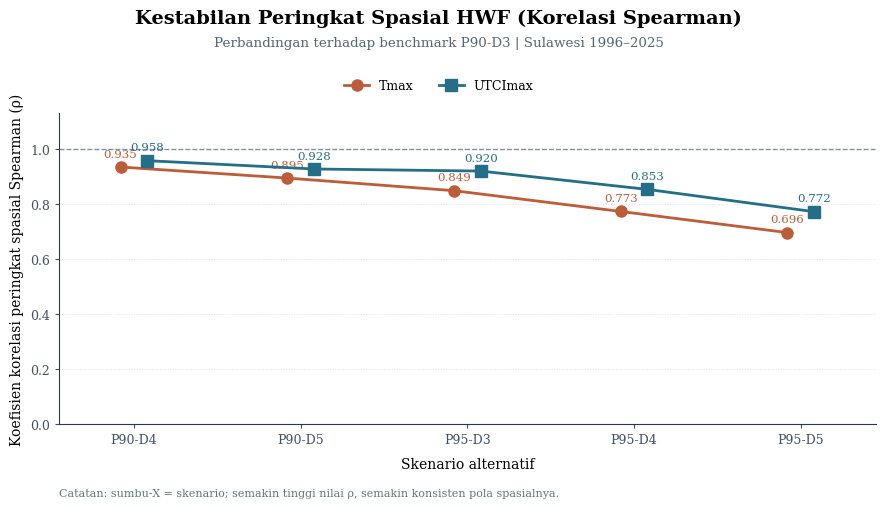

WindowsPath('D:/MERLI/data/TMAX_UTCI_COMPARISON/SENSITIVITAS_FINAL_SKRIPSI_P90D3/figures/FIG01A_MAIN_Spearman_Spatial_HWF_Tmax_UTCImax.png')

In [9]:
# FIGURE 01A — DOT PLOT KHUSUS SPEARMAN, dengan sumbu-X = skenario
fig, ax = plt.subplots(figsize=(9.5, 5.35), facecolor='white')
fig.subplots_adjust(left=.10, right=.96, top=.78, bottom=.20)

scenario_labels = [s.replace('_', '-') for s in OTHER_SCENARIOS]
x = np.arange(len(OTHER_SCENARIOS), dtype=float)
offsets = {'Tmax': -0.08, 'UTCImax': 0.08}
markers = {'Tmax': 'o', 'UTCImax': 's'}

for ind in ['Tmax', 'UTCImax']:
    tab = (summary_df[summary_df.indicator == ind]
           .set_index('scenario')
           .reindex(OTHER_SCENARIOS))
    vals = tab['spearman_rho'].to_numpy(dtype=float)

    ax.plot(x + offsets[ind], vals,
            marker=markers[ind], ms=8, lw=2,
            color=PALETTE[ind], label=ind, zorder=4)

    for xx, value in zip(x + offsets[ind], vals):
        if np.isfinite(value):
            ax.text(xx, value + 0.03, f'{value:.3f}',
                    fontsize=8.5, ha='center', va='bottom', color=PALETTE[ind])

ax.set_xticks(x, scenario_labels)
ax.set_xlim(-0.45, len(x) - 0.55)
ax.set_ylim(0, 1.13)
ax.axhline(1, lw=.95, color='#778899', ls='--', zorder=1)
ax.set_xlabel('Skenario alternatif', fontsize=10, labelpad=8)
ax.set_ylabel('Koefisien korelasi peringkat spasial Spearman (ρ)', fontsize=10)
ax.grid(axis='y', ls=':', lw=.7, alpha=.35)
ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Kestabilan Peringkat Spasial HWF (Korelasi Spearman)', fontsize=14,
             weight='bold', y=.975)
fig.text(.5, .905, 'Perbandingan terhadap benchmark P90-D3 | Sulawesi 1996–2025',
         ha='center', fontsize=9.7, color='#566776')
fig.legend(loc='upper center', bbox_to_anchor=(.5, .865), ncol=2, frameon=False, fontsize=9)
fig.text(.10, .065, 'Catatan: sumbu-X = skenario; semakin tinggi nilai ρ, semakin konsisten pola spasialnya.',
         fontsize=8, color='#627582')
save_figure(fig, 'FIG01A_MAIN_Spearman_Spatial_HWF_Tmax_UTCImax')



## Gambar Utama 2 — P90-D3 dibanding P95-D5 secara spasial (PALING MUDAH DIJELASKAN)
**Disarankan masuk Bab III** sebagai contoh perubahan spasial paling besar. Baris = Tmax dan UTCImax. Kolom = HWF P90-D3, HWF P95-D5, dan **penurunan absolut** dari benchmark (hari/tahun). Skala warna P90-D3 dan P95-D5 dibuat sama untuk dua indikator; skala penurunan juga sama.

✓ D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures\FIG02_MAIN_Benchmark_vs_P95D5_Tmax_UTCImax.png


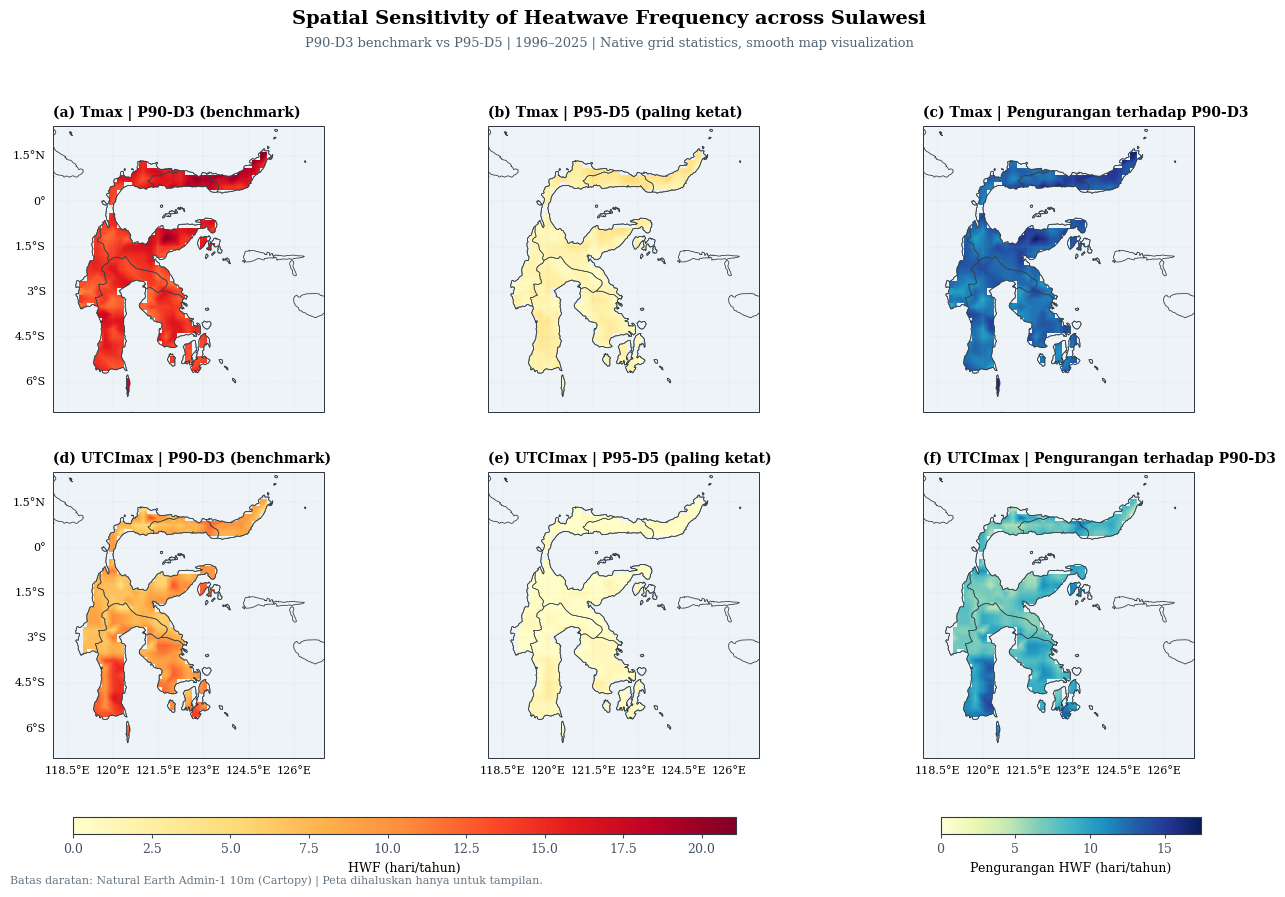

WindowsPath('D:/MERLI/data/TMAX_UTCI_COMPARISON/SENSITIVITAS_FINAL_SKRIPSI_P90D3/figures/FIG02_MAIN_Benchmark_vs_P95D5_Tmax_UTCImax.png')

In [10]:
# FIGURE 02 — PETA SMOOTH SEPERTI NOTEBOOK SPASIAL AWAL (2x3)
strict='P95_D5'
valid_hwf=np.hstack([statistics[i][s]['hwf'][np.isfinite(statistics[i][s]['hwf'])]
                     for i in ['Tmax','UTCImax'] for s in [BENCHMARK,strict]])
valid_loss=np.hstack([(-statistics[i][strict]['delta'])[np.isfinite(statistics[i][strict]['delta'])]
                      for i in ['Tmax','UTCImax']])
hwf_norm=Normalize(vmin=0,vmax=max(1,float(np.max(valid_hwf))))
loss_norm=Normalize(vmin=0,vmax=max(1,float(np.max(valid_loss))))
fig=plt.figure(figsize=(14.1,9.3),facecolor='white')
gs=fig.add_gridspec(2,3,left=.065,right=.955,bottom=.17,top=.85,wspace=.13,hspace=.21)
for row,ind in enumerate(['Tmax','UTCImax']):
    fieldlist=[statistics[ind][BENCHMARK]['hwf'],statistics[ind][strict]['hwf'],
               -statistics[ind][strict]['delta']]
    titles=['P90-D3 (benchmark)','P95-D5 (paling ketat)','Pengurangan terhadap P90-D3']
    for col,(field,ttl) in enumerate(zip(fieldlist,titles)):
        ax=make_map_axis(fig,gs[row,col])
        draw_continuous(ax,ind,field,'YlOrRd' if col<2 else 'YlGnBu',
                        hwf_norm if col<2 else loss_norm)
        decorate_map(ax,f'({chr(97+row*3+col)}) {ind} | {ttl}',
                     left=col==0,bottom=row==1)
fig.suptitle('Spatial Sensitivity of Heatwave Frequency across Sulawesi',
             fontsize=14,weight='bold',y=.975)
fig.text(.5,.935,'P90-D3 benchmark vs P95-D5 | 1996–2025 | Native grid statistics, smooth map visualization',
         ha='center',fontsize=9.4,color='#526372')
cb1=fig.add_axes([.12,.089,.47,.018]);cb2=fig.add_axes([.735,.089,.185,.018])
fig.colorbar(ScalarMappable(cmap='YlOrRd',norm=hwf_norm),cax=cb1,
             orientation='horizontal').set_label('HWF (hari/tahun)',fontsize=9)
fig.colorbar(ScalarMappable(cmap='YlGnBu',norm=loss_norm),cax=cb2,
             orientation='horizontal').set_label('Pengurangan HWF (hari/tahun)',fontsize=9)
fig.text(.075,.035,f'Batas daratan: {GEOMETRY_SOURCE} | Peta dihaluskan hanya untuk tampilan.',
         fontsize=8,color='#667684')
save_figure(fig,'FIG02_MAIN_Benchmark_vs_P95D5_Tmax_UTCImax')


## Gambar pendukung — peta penurunan persentase terhadap P90-D3
Peta **lima skenario** ini memperlihatkan perubahan HWF per grid. Panel keenam berisi penjelasan. Skala warna tetap 0–100% untuk setiap provinsi dan skenario. **Nilai 0 pada denominator tidak diubah jadi 0%**: grid tanpa HWF pada benchmark tetap dikosongkan.


✓ D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures\FIG03_SUPPORT_Spatial_Percent_Reduction_Tmax.png


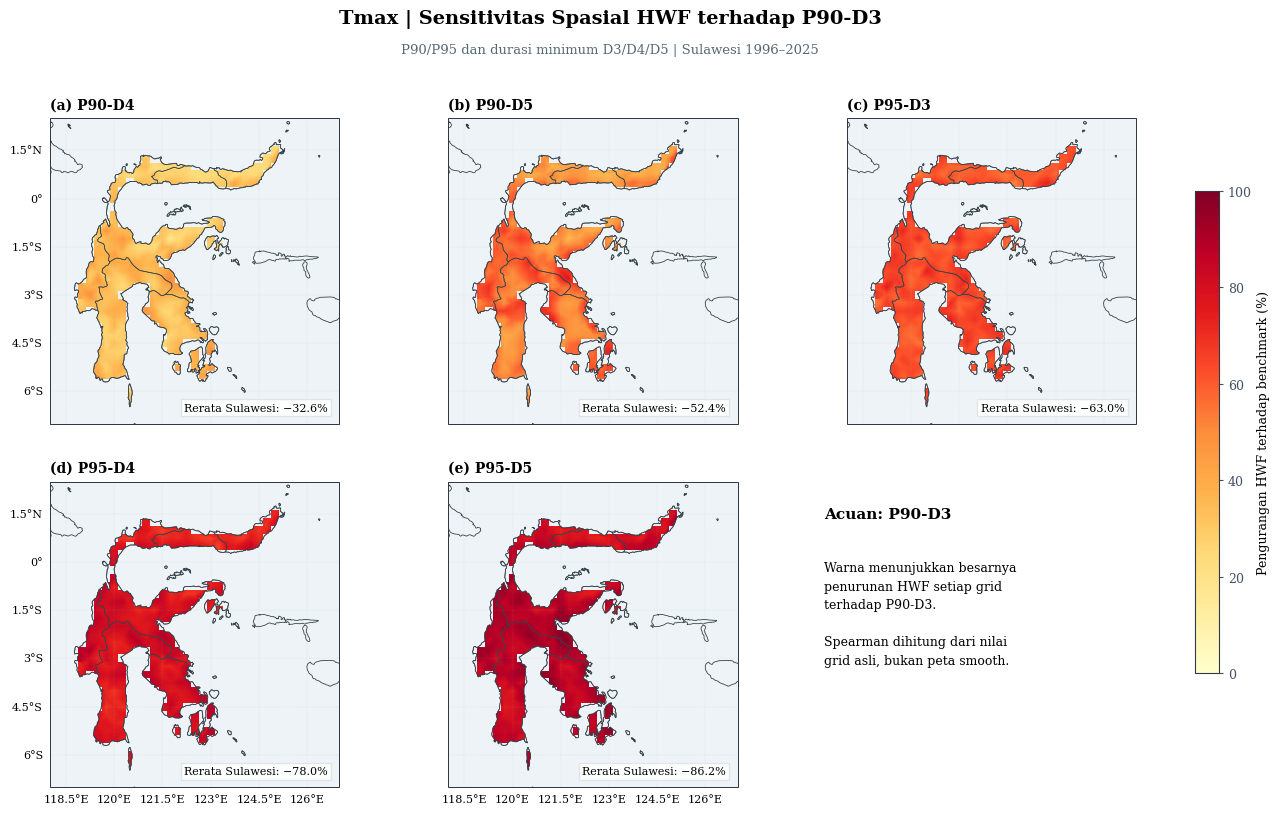

✓ D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures\FIG03_SUPPORT_Spatial_Percent_Reduction_UTCImax.png


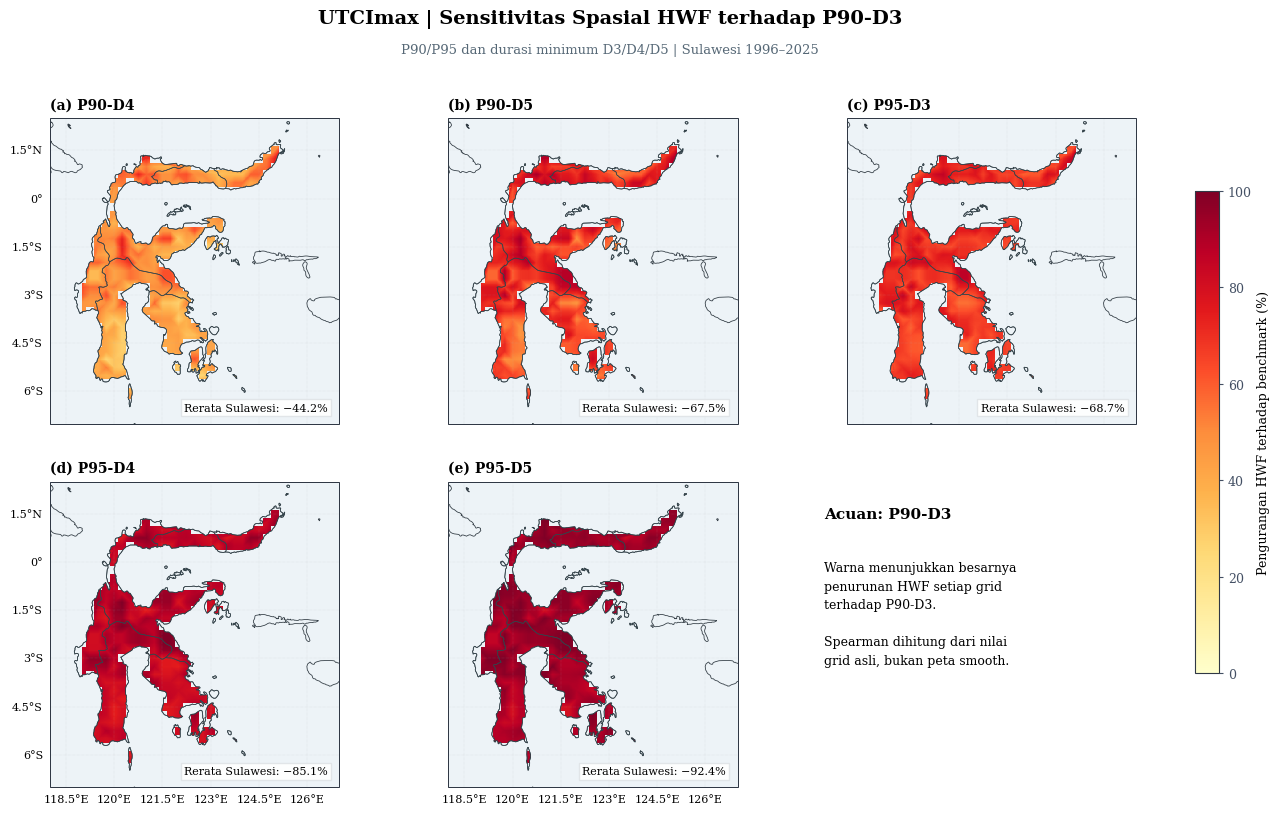

In [11]:
# FIGURES 03–04 — 5 SKENARIO, PETA SMOOTH + BATAS PROVINSI
for ind in ['Tmax','UTCImax']:
    fig=plt.figure(figsize=(13.8,9.1),facecolor='white')
    gs=fig.add_gridspec(2,3,left=.07,right=.905,bottom=.12,top=.855,
                        wspace=.12,hspace=.19)
    for i,sc in enumerate(OTHER_SCENARIOS):
        row,col=divmod(i,3)
        ax=make_map_axis(fig,gs[row,col])
        draw_continuous(ax,ind,statistics[ind][sc]['reduction'],'YlOrRd',Normalize(0,100))
        reg=float(summary_df.loc[(summary_df.indicator==ind)&(summary_df.scenario==sc),
                                  'reduction_regional_percent'].iloc[0])
        decorate_map(ax,f'({chr(97+i)}) {sc.replace("_","-")}',left=col==0,bottom=row==1)
        ax.text(.96,.035,f'Rerata Sulawesi: −{reg:.1f}%',transform=ax.transAxes,
                fontsize=8,ha='right',va='bottom',zorder=9,
                bbox=dict(facecolor='white',alpha=.92,edgecolor='#e0e4e7',pad=2.5))
    ax_note=fig.add_subplot(gs[1,2]);ax_note.axis('off')
    ax_note.text(.03,.88,'Acuan: P90-D3',fontsize=11,weight='bold',transform=ax_note.transAxes)
    ax_note.text(.03,.74,'Warna menunjukkan besarnya\npenurunan HWF setiap grid\nterhadap P90-D3.\n\n'
                  'Spearman dihitung dari nilai\ngrid asli, bukan peta smooth.',
                  fontsize=9,linespacing=1.55,va='top',transform=ax_note.transAxes)
    fig.suptitle(f'{ind} | Sensitivitas Spasial HWF terhadap P90-D3',fontsize=14,weight='bold',y=.975)
    fig.text(.50,.927,'P90/P95 dan durasi minimum D3/D4/D5 | Sulawesi 1996–2025',
             fontsize=9.5,ha='center',color='#566876')
    cb=fig.add_axes([.924,.245,.017,.53])
    fig.colorbar(ScalarMappable(cmap='YlOrRd',norm=Normalize(0,100)),cax=cb).set_label(
        'Pengurangan HWF terhadap benchmark (%)',fontsize=9)
    save_figure(fig,f'FIG03_SUPPORT_Spatial_Percent_Reduction_{ind}')


## Gambar opsional — kategori hotspot (native, tanpa smoothing)
Hotspot merupakan **kategori diskret** yang tidak boleh diinterpolasi secara linear. Warna kategori ditampilkan pada grid asli; batas provinsi tetap mengikuti SHP. Jaccard menunjukkan persentase kesamaan relatif lokasi hotspot, bukan nilai intensitas panas.


✓ D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures\FIG05_OPTIONAL_P95D5_Hotspot_Persistence.png


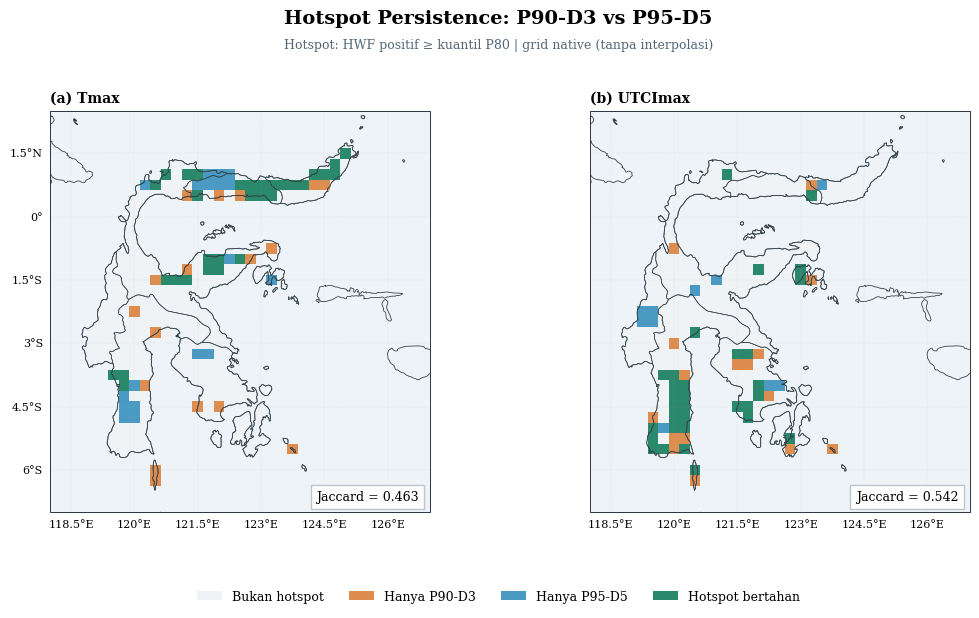

In [12]:
# FIGURE 05 — HOTSPOT KATEGORIK PADA GRID NATIVE (TIDAK DIHALUSKAN)
if MAKE_OPTIONAL_HOTSPOT_FIGURE:
    hotspot_colors=['#f0f3f5','#de8d50','#4a9ac4','#2a896b']
    hotspot_cmap=ListedColormap(hotspot_colors)
    hotspot_norm=BoundaryNorm([-.5,.5,1.5,2.5,3.5],4)
    fig=plt.figure(figsize=(11.2,6.8),facecolor='white')
    gs=fig.add_gridspec(1,2,left=.07,right=.95,bottom=.22,top=.81,wspace=.21)
    for i,ind in enumerate(['Tmax','UTCImax']):
        ax=make_map_axis(fig,gs[i])
        col=collections[ind]
        z=statistics[ind]['P95_D5']['hotspot_class'].astype(float).copy()
        z[z<0]=np.nan
        kw={'cmap':hotspot_cmap,'norm':hotspot_norm,'rasterized':True,'zorder':2}
        if HAS_CARTOPY:kw['transform']=ccrs.PlateCarree()
        ax.pcolormesh(col['lon'],col['lat'],np.ma.masked_invalid(z),shading='nearest',**kw)
        decorate_map(ax,f'({chr(97+i)}) {ind}',left=i==0,bottom=True)
        j=float(summary_df.loc[(summary_df.indicator==ind)&(summary_df.scenario=='P95_D5'),
                               'hotspot_jaccard'].iloc[0])
        ax.text(.97,.03,f'Jaccard = {j:.3f}',transform=ax.transAxes,
                fontsize=9,ha='right',bbox=dict(facecolor='white',alpha=.95,edgecolor='#b9c4cc'))
    fig.suptitle('Hotspot Persistence: P90-D3 vs P95-D5',fontsize=14,weight='bold',y=.96)
    fig.text(.5,.903,'Hotspot: HWF positif ≥ kuantil P80 | grid native (tanpa interpolasi)',
             fontsize=9,ha='center',color='#546777')
    labels=['Bukan hotspot','Hanya P90-D3','Hanya P95-D5','Hotspot bertahan']
    handles=[mpatches.Patch(facecolor=hotspot_colors[i],label=labels[i]) for i in range(4)]
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,.07),ncol=4,frameon=False)
    save_figure(fig,'FIG05_OPTIONAL_P95D5_Hotspot_Persistence')


## FIGURE 06 — Scatter Spearman pada grid asli (pelengkap pembuktian)
Dua panel dengan sumbu X = HWF P90-D3 dan Y = HWF P95-D5 (hari/tahun). **Setiap titik adalah satu grid Sulawesi**, bukan satu provinsi atau satu tahun. Annotasi Spearman ρ dihitung dari grid native yang sama.


✓ D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures\FIG06_SUPPORT_Scatter_Spearman_P90D3_vs_P95D5.png


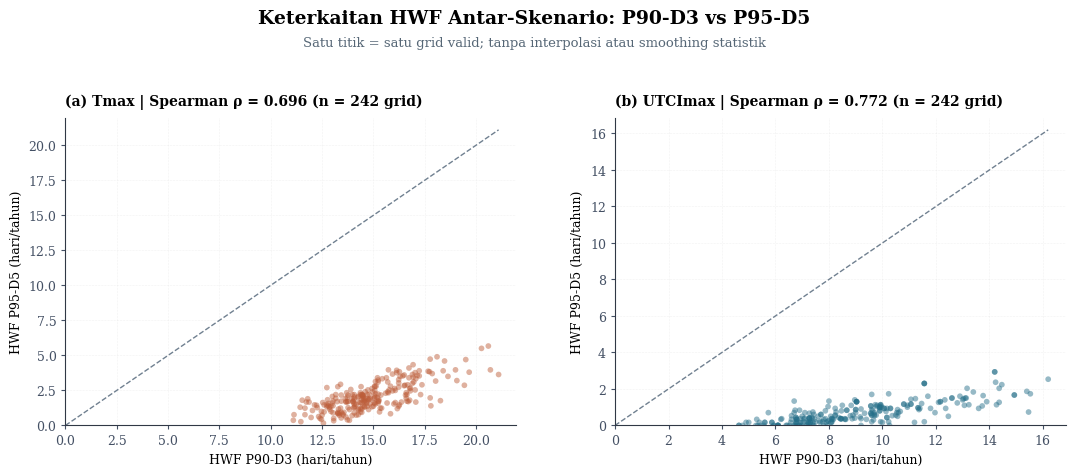

WindowsPath('D:/MERLI/data/TMAX_UTCI_COMPARISON/SENSITIVITAS_FINAL_SKRIPSI_P90D3/figures/FIG06_SUPPORT_Scatter_Spearman_P90D3_vs_P95D5.png')

In [13]:
# FIGURE 06 — NATIVE-GRID SCATTER P90-D3 vs P95-D5; SPEARMAN ρ
fig,axarr=plt.subplots(1,2,figsize=(11.3,5.3),facecolor='white')
fig.subplots_adjust(left=.085,right=.97,top=.77,bottom=.19,wspace=.22)
for k,ind in enumerate(['Tmax','UTCImax']):
    ax=axarr[k]
    col=collections[ind]
    ref=statistics[ind][BENCHMARK]['hwf']; alt=statistics[ind]['P95_D5']['hwf']
    valid=col['valid'] & np.isfinite(ref) & np.isfinite(alt)
    x,y=ref[valid],alt[valid]
    rho=safe_correlations(ref,alt,valid)[0]
    ax.scatter(x,y,s=17,alpha=.48,color=PALETTE[ind],edgecolor='none',rasterized=True)
    mx=max(1.,float(np.max(x)),float(np.max(y)))
    ax.plot([0,mx],[0,mx],ls='--',color='#708090',lw=1,label='1:1 reference')
    ax.set_xlim(0,mx*1.04);ax.set_ylim(0,mx*1.04)
    ax.set_xlabel('HWF P90-D3 (hari/tahun)',fontsize=9)
    ax.set_ylabel('HWF P95-D5 (hari/tahun)',fontsize=9)
    ax.set_title(f'({chr(97+k)}) {ind} | Spearman ρ = {rho:.3f} (n = {len(x)} grid)',
                 loc='left',weight='bold',fontsize=10,pad=9)
    ax.grid(ls=':',alpha=.3)
    ax.spines[['top','right']].set_visible(False)
fig.suptitle('Keterkaitan HWF Antar-Skenario: P90-D3 vs P95-D5',
             fontsize=13.5,weight='bold',y=.975)
fig.text(.5,.905,'Satu titik = satu grid valid; tanpa interpolasi atau smoothing statistik',
         ha='center',fontsize=9.5,color='#566776')
save_figure(fig,'FIG06_SUPPORT_Scatter_Spearman_P90D3_vs_P95D5')


## 4 — Ekspor semua tabel dan peta numerik (bukan hasil interpolasi)
Semua nilai mentah klimatologi HWF, penurunan absolut, penurunan persen, dan kategori hotspot disimpan dalam NetCDF terpisah untuk Tmax dan UTCImax; tabel juga disimpan CSV dan Excel. Angka pada gambar bukan diketik manual: semuanya diperoleh dari `summary_df` setelah proses *load* dan QC.

In [14]:
summary_file=TABLE_DIR/'TABEL_LENGKAP_SpatialSensitivity_HWF_P90D3_1996_2025.csv'
summary_df.to_csv(summary_file,index=False,float_format='%.6f')
for ind,col in collections.items():
    st=statistics[ind]
    ds=xr.Dataset(
        data_vars={
            'HWF':(('scenario','latitude','longitude'),np.stack([st[s]['hwf'] for s in SCENARIOS]).astype('float32')),
            'HWF_delta_scenario_minus_benchmark':(('scenario','latitude','longitude'),np.stack([st[s]['delta'] for s in SCENARIOS]).astype('float32')),
            'HWF_reduction_percent':(('scenario','latitude','longitude'),np.stack([st[s]['reduction'] for s in SCENARIOS]).astype('float32')),
            'hotspot_class':(('scenario','latitude','longitude'),np.stack([st[s]['hotspot_class'] for s in SCENARIOS]).astype('int16'))},
        coords={'scenario':SCENARIOS,'latitude':col['lat'],'longitude':col['lon']},
        attrs={'indicator':ind,'baseline':BENCHMARK,'period':'1996-2025',
               'weights':'cos(latitude)', 'hotspot_top_fraction':HOTSPOT_TOP_FRACTION,
               'geospatial_interpolation':'NONE; numeric data native grid'})
    ds['HWF'].attrs['units']='days/year'
    ds['HWF_delta_scenario_minus_benchmark'].attrs['units']='days/year'
    ds['HWF_reduction_percent'].attrs['units']='percent'
    outfile=MAP_DIR/f'{ind}_Sensitivity_NATIVE_1996_2025.nc'
    ds.to_netcdf(outfile)
    ds.close()
    print('✓ NetCDF:',outfile)
meta={'period':'1996-2025','baseline':BENCHMARK,'scenarios':SCENARIOS,
      'hotspot_fraction':HOTSPOT_TOP_FRACTION,'weights':'cos(latitude)',
      'smoothed_maps_only':EFFECTIVE_RENDER=='smooth',
      'Spearman':'descriptive spatial ranks; no spatial-autocorrelation-adjusted p-values',
      'HWF_metric_source':'original Tmax .npz and UTCI .nc annual metric caches'}
(OUTPUT_DIR/'metadata_FINAL.json').write_text(json.dumps(meta,indent=2,ensure_ascii=False),encoding='utf-8')
print('\nTabel utama:',TABLE_DIR/'TABEL_UTAMA_SENSITIVITAS_P90D3.csv')
print('Tabel lengkap:',summary_file)
print('Semua gambar:',PLOT_DIR)

✓ NetCDF: D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\maps_netcdf\Tmax_Sensitivity_NATIVE_1996_2025.nc
✓ NetCDF: D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\maps_netcdf\UTCImax_Sensitivity_NATIVE_1996_2025.nc

Tabel utama: D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\tables\TABEL_UTAMA_SENSITIVITAS_P90D3.csv
Tabel lengkap: D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\tables\TABEL_LENGKAP_SpatialSensitivity_HWF_P90D3_1996_2025.csv
Semua gambar: D:\MERLI\data\TMAX_UTCI_COMPARISON\SENSITIVITAS_FINAL_SKRIPSI_P90D3\figures


## Panduan pemilihan gambar untuk Bab III

**Masukkan ke hasil utama:** `FIG01A_MAIN` (grafik Spearman yang jelas), `FIG01_MAIN` (komparasi Spearman–penurunan HWF–Jaccard), dan `FIG02_MAIN` (peta smooth P90-D3 vs P95-D5).

**Pendukung/lampiran:** `FIG03_SUPPORT` masing-masing indikator (lima skenario penurunan HWF), `FIG05_OPTIONAL` kategori hotspot (native, tidak di-smooth), dan `FIG06_SUPPORT` scatter Spearman terhadap benchmark.

**Penting:** P90-D3 adalah *benchmark internal*. Spearman tinggi = peringkat HWF antargrid relatif konsisten; HWF tetap bisa menurun besar. Penyimpulan signifikansi korelasi spasial memerlukan mempertimbangkan autokorelasi grid; plot ini bersifat deskriptif.
